# MyFinSight 분석 결과 한눈에 보기

`output/13_results.json` 하나만 읽어서, 파이프라인이 **무엇을 받아(요청) → 어떻게 이해하고(의도) → 어떤 종목을 골라(선정) → 어떻게 나누고(구성) → 과거에 적용하면 어땠고(백테스트) → 기준을 통과했는지(검증)** 를 순서대로 보여줍니다.
각 절의 표와 그래프는 모두 같은 결과 파일의 숫자입니다.

In [1]:
import json, math
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import matplotlib as mpl

mpl.rcParams["font.family"] = "AppleGothic"      # macOS 한글 폰트 (다른 OS: 'Malgun Gothic' / 'NanumGothic')
mpl.rcParams["axes.unicode_minus"] = False
pd.set_option("display.max_colwidth", 80); pd.set_option("display.width", 160)

import os
RESULTS = Path(os.environ.get("MYFINSIGHT_RESULTS", "../output/13_results.json"))   # 기본: notebooks/ 기준 상대 경로
R = json.loads(RESULTS.read_text(encoding="utf-8"))
pct = lambda x: "–" if x is None else f"{x*100:+.2f}%"
pct1 = lambda x: "–" if x is None else f"{x*100:.1f}%"
usd = lambda x: "–" if x is None else f"{x:,.2f} USD"
krw = lambda x: "–" if x is None else f"{x:,.0f}원"
print("request_id:", R["request_id"], "| generated:", R["generated_at"], "| pipeline:", R["pipeline_version"])

request_id: req_2026-10-10_hc1 | generated: 2026-10-10T02:04:55 | pipeline: mockup-2026.10


## 1. 요청 — 사용자가 입력한 것

In [2]:
q, d, c, h, r = R["request"], R["request"]["derived"], R["request"]["capital"], R["request"]["horizon"], R["request"]["risk"]
rows = [("투자금", f"{c['initial_amount']:,.0f}원 → {usd(d['initial_amount_usd'])}  (환율 {R['money_krw']['direction']}, {d['fx_date']})"),
        ("월 적립", f"{c['monthly_contribution']:,.0f}원 (매월 {c['contribution_day']}일) → {usd(d['monthly_contribution_usd'])}"),
        ("투자기간", f"{h['target_years']}년, 시작 희망일 {h['start_date']}"),
        ("투자성향", f"{r['risk_tolerance']} · 손실 감내 수준 {r['max_drawdown_tolerance']:.0%} · 손실 시 {r['loss_reaction']}"),
        ("목표 수익률 / 비교지수", f"연 {r['target_annual_return']:.0%} / {r['benchmark']}"),
        ("전략 템플릿 / 기준 비중", f"{q['strategy_preference']['template']} / {q['strategy_preference']['baseline_weighting']}"),
        ("투자 아이디어", q["natural_language"]["idea"])]
pd.DataFrame(rows, columns=["항목", "내용"]).set_index("항목")

,내용
항목,
투자금,"10,000,000원 → 7,467.81 USD (환율 1 USD = 1,339.08 KRW, 2026-10-08)"
월 적립,"500,000원 (매월 25일) → 373.39 USD"
투자기간,"3.0년, 시작 희망일 2026-10-08"
투자성향,moderate · 손실 감내 수준 25% · 손실 시 hold
목표 수익률 / 비교지수,연 12% / SPY
전략 템플릿 / 기준 비중,momentum / equal_weight
투자 아이디어,"헬스케어 쪽에 투자하고 싶어요. 비만·당뇨 치료제, 의료기기, 헬스케어 서비스처럼 고령화와 신약 수요로 성장하는 기업 중 최근 1년 주가..."


## 2. 의도 해석 — 분석 모델이 아이디어를 어떻게 이해했나

In [3]:
I = R["intent"]
print(I["interpretation"]["summary_ko"]); print()
themes = pd.DataFrame([{"테마": t["label_ko"], "설명": t["description_ko"], "GICS 코드": ", ".join(t["gics_codes"]), "키워드": ", ".join(t["keywords"][:6])} for t in I["interpretation"]["themes"]])
display(themes.set_index("테마"))
cons = q["constraints"]
display(pd.DataFrame([("종목 수", f"목표 {cons['num_holdings']['target']} (허용 {cons['num_holdings']['min']}~{cons['num_holdings']['max']})"), ("종목당 상한", f"{cons['max_weight_per_stock']:.0%}"), ("섹터당 상한", f"{cons['max_weight_per_sector']:.0%}"),
                      ("리밸런싱", d["rebalance_rule"]["description_ko"]), ("제외 테마", ", ".join(cons["exclude_themes"]) or "없음"),
                      ("변동성 선호 / 허용 MDD", f"{I['risk_params']['volatility_preference']} / {I['risk_params']['effective_max_drawdown']:.0%}"), ("해석 메모", I["risk_params"]["notes_ko"])], columns=["항목", "값"]).set_index("항목"))
if I["interpretation"]["conflicts"]:
    display(pd.DataFrame(I["interpretation"]["conflicts"]).rename(columns={"field": "항목", "issue_ko": "확인한 점", "resolution_ko": "처리"}))

비만·당뇨 치료제, 의료기기, 헬스케어 서비스 등 고령화와 신약 수요의 수혜가 가능한 헬스케어 기업에 투자하려는 의도입니다. 최근 1년 주가 흐름이 좋은 종목을 기준으로 분산해 3년 보유하되, 임상 실패 위험이 큰 소형 바이오는 피하려는 선호를 반영합니다.



,설명,GICS 코드,키워드
테마,,,
비만·당뇨 치료제,비만 또는 당뇨 치료용 의약품을 개발·제조·판매하는 제약 및 바이오 기업입니다. 특히 상용화된 치료제나 규모가 큰 기업을 중심으로 분류하...,"35201010, 35202010","glp-1, obesity drug, diabetes drug, weight loss drug, metabolic disease, ins..."
헬스케어 의료기기,"진단·치료·환자 모니터링에 쓰이는 의료기기와 의료용품을 개발·제조하는 기업입니다. 당뇨 관리 기기, 연속혈당측정기, 인슐린 펌프, 수술·...","35101010, 35101020","medical device, continuous glucose monitoring, glucose monitor, insulin pump..."
헬스케어 서비스,"병원·의료시설 운영, 의료서비스 제공, 건강보험 관리, 의료 유통 및 헬스케어 기술 서비스를 통해 의료 접근성과 운영을 지원하는 기업입니...","35102010, 35102015, 35102020, 35102030, 35103010","healthcare services, health insurance, managed care, hospital operator, heal..."


,값
항목,
종목 수,목표 15 (허용 10~20)
종목당 상한,15%
섹터당 상한,100%
리밸런싱,1×2주마다 리밸런싱
제외 테마,"tobacco, gambling"
변동성 선호 / 허용 MDD,medium / 25%
해석 메모,손실 발생 시 hold를 선택했고 투자 경험이 beginner이므로 지침상 최대 낙폭 조정 요인은 없습니다. 하드 기준인 최대 낙폭 0....


,항목,확인한 점,처리
0,natural_language.idea 및 constraints.min_market_cap_usd,"임상 실패 위험이 큰 소형 바이오를 피하고 싶다는 선호와 최소 시가총액 200억 달러라는 하드 조건은 대체로 같은 방향이지만, 시가총액만...","최소 시가총액 200억 달러 하드 조건을 그대로 적용하고, 테마 분류에서도 초기 단계 임상 중심 기업은 사용자의 선호에 따라 제외하도록 ..."


## 3. 종목 선정 — 깔때기와 선정 표

유니버스 → 테마 관련 후보(GICS·키워드) → 테마 해당 판정(분석 모델) → 선정 지표 순위 → 섹터 상한 → 최종. 백테스트는 시작일 당시 정보로 같은 규칙을 다시 적용하므로 목록이 다를 수 있습니다.

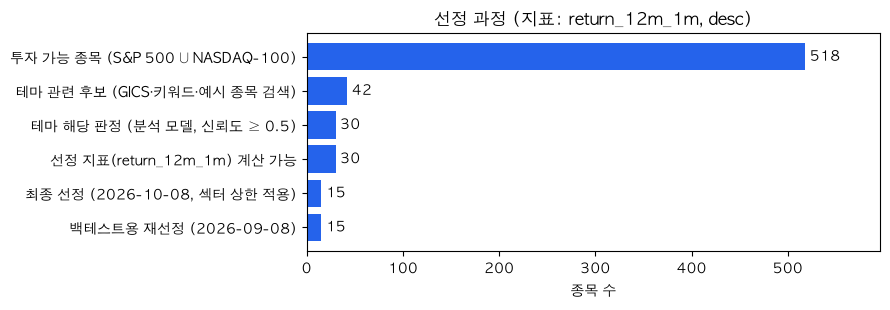

,회사,섹터,테마,신뢰도,순위(2026-09-08),지표(백테스트),순위(2026-10-08),지표(2026),테마 판정 사유
티커,,,,,,,,,
CNC,Centene Corporation,Health Care,healthcare_services,0.95,1.0,+126.95%,3.0,+66.74%,저소득층·보험 가입자를 위한 관리형 건강보험을 운영
LLY,Lilly (Eli),Health Care,obesity_diabetes_treatments,0.98,2.0,+63.84%,8.0,+34.10%,Mounjaro·Zepbound 등 당뇨·비만 치료제가 핵심 제품
CAH,Cardinal Health,Health Care,healthcare_services,0.90,3.0,+59.71%,4.0,+54.30%,의약품·의료용품 유통으로 의료기관 운영을 지원
MRK,Merck & Co.,Health Care,obesity_diabetes_treatments,0.75,4.0,+56.86%,1.0,+72.32%,Januvia·Janumet 등 당뇨 치료제를 판매
AMGN,Amgen,Health Care,obesity_diabetes_treatments,0.50,5.0,+48.04%,7.0,+36.06%,비만 치료 후보 MariTide를 개발 중인 대형 제약사
JNJ,Johnson & Johnson,Health Care,"obesity_diabetes_treatments, healthcare_medical_devices",0.55,6.0,+47.83%,5.0,+44.58%,Invokana 당뇨약과 수술·정형외과 등 의료기기 사업을 보유
WST,West Pharmaceutical Services,Health Care,healthcare_medical_devices,0.55,7.0,+41.66%,11.0,+27.08%,주사용 의약품 포장·투여용 부품과 의료용품을 제조
CVS,CVS Health,Health Care,healthcare_services,0.95,8.0,+33.83%,10.0,+27.60%,약국·보험·약국급여관리와 클리닉을 운영
UNH,UnitedHealth Group,Health Care,healthcare_services,0.98,9.0,+32.53%,NaN,+nan%,건강보험과 Optum 의료·약국관리 서비스를 운영


백테스트 재선정에서 추가: ['ELV', 'UNH'] | 빠짐: ['DXCM', 'VTRS']


,회사,제외 이유,지표값
티커,,,
ELV,Elevance Health,rank_beyond_n,0.127411
EW,Edwards Lifesciences,rank_beyond_n,0.123306
UNH,UnitedHealth Group,rank_beyond_n,0.102834
COR,Cencora,rank_beyond_n,0.055307
HCA,HCA Healthcare,rank_beyond_n,-0.031164
MDT,Medtronic,rank_beyond_n,-0.042373
CI,Cigna,rank_beyond_n,-0.073795
STE,Steris,rank_beyond_n,-0.101927


In [4]:
S = R["selection"]
f = pd.DataFrame(S["funnel"])
fig, ax = plt.subplots(figsize=(9, 3.2))
ax.barh(f["label_ko"][::-1], f["count"][::-1], color="#2563eb")
for i, v in enumerate(f["count"][::-1]): ax.text(v + 5, i, str(v), va="center")
ax.set_xlabel("종목 수"); ax.set_title(f"선정 과정 (지표: {S['metric']}, {S['direction']})"); ax.set_xlim(0, f["count"].max() * 1.15)
plt.tight_layout(); plt.show()

t = pd.DataFrame(S["table"])
view = t[["ticker", "name", "sector", "themes", "theme_confidence", "rank_backtest", "metric_backtest", "rank_2026", "metric_2026", "theme_reason_ko"]].copy()
view["themes"] = view["themes"].str.join(", "); view["metric_backtest"] = view["metric_backtest"].map(pct); view["metric_2026"] = view["metric_2026"].map(pct)
view.columns = ["티커", "회사", "섹터", "테마", "신뢰도", f"순위({S['backtest_as_of']['as_of']})", "지표(백테스트)", f"순위({S['as_of_2026']['as_of']})", "지표(2026)", "테마 판정 사유"]
display(view.set_index("티커"))
diff = S["backtest_as_of"]["diff_vs_original"]
print("백테스트 재선정에서 추가:", diff["added"], "| 빠짐:", diff["removed"])
display(pd.DataFrame(S["as_of_2026"]["rejected_examples"]).rename(columns={"ticker": "티커", "name": "회사", "reason": "제외 이유", "metric_value": "지표값"}).set_index("티커"))

## 4. 포트폴리오 구성 — 기준 비중, 규칙 4가지, 시나리오 5개

기준은 1/N 동일비중이고, 종목·섹터 상한으로 재배분합니다. Black-Litterman 타겟은 기준 비중에 시나리오 뷰를 종목당 최대 `max_tilt` 만큼만 반영한 것입니다.

,섹터,1/N,최종 비중
CNC,Health Care,6.7%,6.7%
LLY,Health Care,6.7%,6.7%
CAH,Health Care,6.7%,6.7%
MRK,Health Care,6.7%,6.7%
AMGN,Health Care,6.7%,6.7%
JNJ,Health Care,6.7%,6.7%
WST,Health Care,6.7%,6.7%
CVS,Health Care,6.7%,6.7%
UNH,Health Care,6.7%,6.7%
DGX,Health Care,6.7%,6.7%


적용된 제약: [] | 섹터 비중: {'Health Care': 1.0}


,설명,예상 변동성,유효 종목 수,최대 비중
규칙,,,,
동일비중,모든 종목에 같은 비중 1/N,15.0%,15.0,6.7%
시가총액비중,시가총액에 비례한 비중 (지수 방식),15.7%,8.9,15.0%
역변동성비중,변동성이 낮은 종목에 더 큰 비중 (1/σ 정규화),14.1%,14.2,9.7%
최소분산,포트폴리오 분산을 최소화하는 비중 (제약 포함 최적화),13.4%,10.8,15.0%


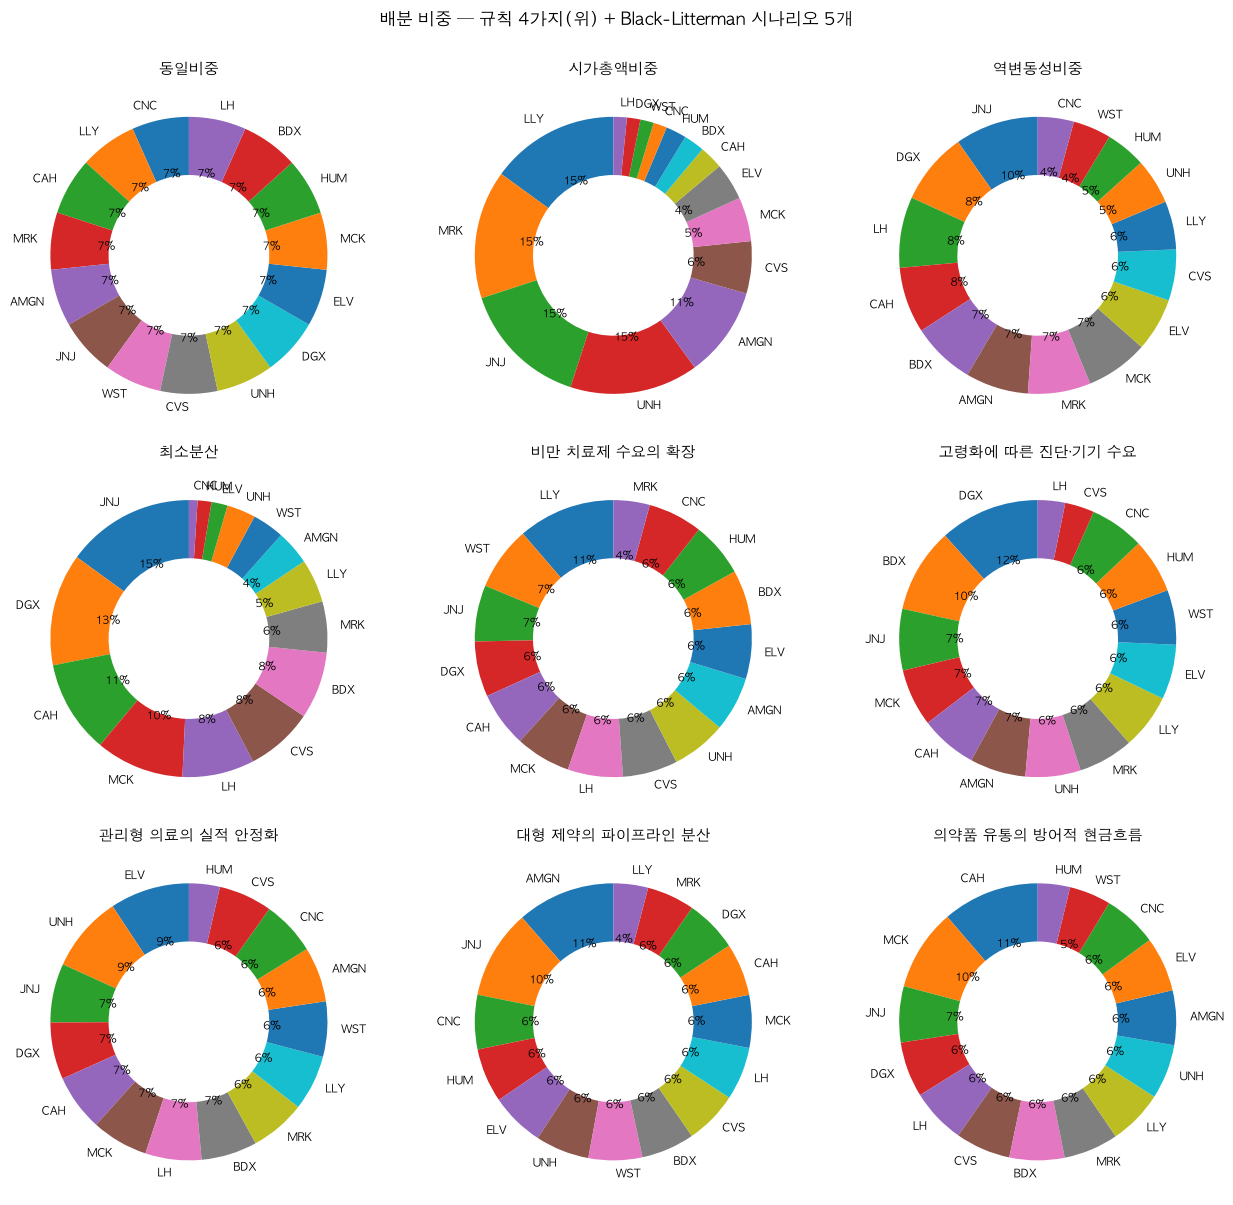

In [5]:
P = R["portfolio"]; base = next(p for p in P["baselines"]["portfolios"] if p["id"] == P["baselines"]["chosen_baseline"])
n = len(base["weights"]); sec = {x["ticker"]: x["sector"] for x in S["table"]}
bt_ = pd.DataFrame({"섹터": {t: sec.get(t, "") for t in base["weights"]}, "1/N": {t: 1/n for t in base["weights"]}, "최종 비중": base["weights"]})
display(bt_.style.format({"1/N": "{:.1%}", "최종 비중": "{:.1%}"}))
print("적용된 제약:", base["constraints_applied"], "| 섹터 비중:", {k: round(v, 3) for k, v in base["sector_weights"].items()})

tmpl = pd.DataFrame([{"규칙": p["name_ko"], "설명": p["rule_ko"], "예상 변동성": p["ex_ante"]["vol"], "유효 종목 수": p["ex_ante"]["effective_n"], "최대 비중": max(p["weights"].values())} for p in P["baselines"]["portfolios"]])
display(tmpl.set_index("규칙").style.format({"예상 변동성": "{:.1%}", "최대 비중": "{:.1%}", "유효 종목 수": "{:.1f}"}))

ports = P["baselines"]["portfolios"] + P["targets"]["portfolios"]
fig, axes = plt.subplots(3, 3, figsize=(13, 12))
for ax, p in zip(axes.flat, ports):
    items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
    ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
    ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=11)
plt.suptitle("배분 비중 — 규칙 4가지(위) + Black-Litterman 시나리오 5개", y=1.0); plt.tight_layout(); plt.show()

,관점,뷰,최대 변화,예상 수익,예상 변동성
시나리오,,,,,
비만 치료제 수요의 확장,비만·당뇨 치료제 수요가 이어지면 상용화 역량과 공급망을 갖춘 기업에 유리한 환경이 될 수 있습니다. 포트폴리오에서는 릴리와 의약품 포장·공급망 관련 기업에 상대적으로 우호적인 방향을 둡니다.,[절대] LLY +20%/년 (신뢰 0.38) / [절대] WST +21%/년 (신뢰 0.30) / [상대] LLY > MRK +8%/년 (신뢰 0.36) / [상대] WST > BDX +6%/년 (신뢰 0.28),+4.7%,15.3%,15.4%
고령화에 따른 진단·기기 수요,고령화로 만성질환의 진단과 지속 관리 수요가 늘면 검사 서비스와 의료기기 업체에 기회가 될 수 있습니다. 단일 신약 성공에 기대기보다 진단·의료기기 노출을 보완하는 시나리오입니다.,[절대] DGX +12%/년 (신뢰 0.31) / [절대] BDX +15%/년 (신뢰 0.29) / [상대] DGX > LH +5%/년 (신뢰 0.27) / [상대] BDX+DGX > CVS +7%/년 (신뢰 0.26),+5.0%,14.5%,15.0%
관리형 의료의 실적 안정화,"보험·관리형 의료 기업은 의료 이용률과 비용 관리에 따라 실적 변동성이 커질 수 있지만, 비용 통제가 자리 잡으면 회복 여지가 있습니다. 이 시나리오는 대형 사업자의 운영 역량을 선호하되 불확실성을 반영해 확신도는 제한합니다.",[절대] UNH +24%/년 (신뢰 0.28) / [절대] ELV +23%/년 (신뢰 0.27) / [상대] UNH+ELV > HUM +8%/년 (신뢰 0.25) / [상대] ELV > CVS +6%/년 (신뢰 0.24),+3.1%,15.0%,15.3%
대형 제약의 파이프라인 분산,대형 제약사는 기존 제품 현금흐름과 연구개발 파이프라인을 함께 활용해 개별 임상 결과의 충격을 줄일 수 있습니다. 이 관점에서는 한 가지 치료 영역에만 집중하기보다 제품·사업 구성이 다양한 기업을 선호합니다.,[절대] MRK +17%/년 (신뢰 0.30) / [절대] AMGN +18%/년 (신뢰 0.31) / [상대] AMGN+JNJ > MRK +6%/년 (신뢰 0.25) / [상대] JNJ > LLY +5%/년 (신뢰 0.22),+4.8%,15.1%,15.1%
의약품 유통의 방어적 현금흐름,"의약품 유통은 치료제 수요와 의료 이용을 지원하는 기반 사업으로, 경기와 무관한 수요가 방어력을 제공할 수 있습니다. 성장주 쏠림을 낮추고 유통·서비스 기업을 함께 보유하는 방향의 시나리오입니다.",[절대] CAH +13%/년 (신뢰 0.31) / [절대] MCK +14%/년 (신뢰 0.31) / [상대] CAH+MCK > WST +5%/년 (신뢰 0.25) / [상대] CAH > HUM +6%/년 (신뢰 0.24),+4.6%,14.1%,14.8%


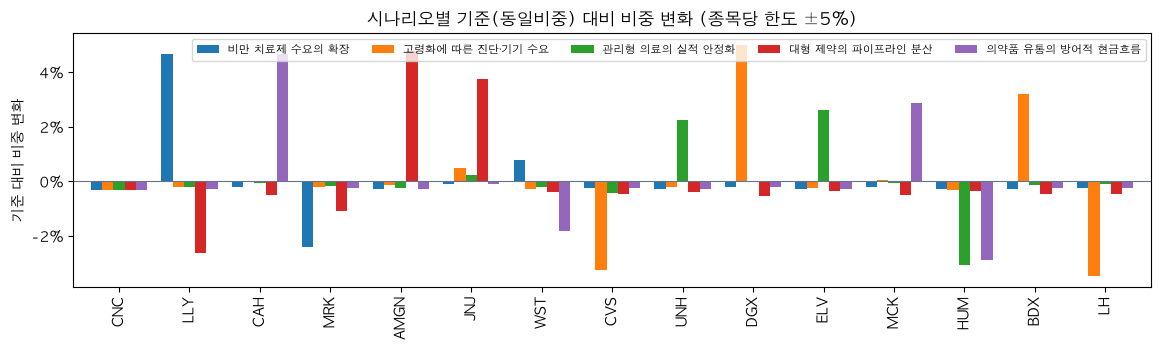

In [6]:
sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                    "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in P["targets"]["portfolios"]])
display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
dl = pd.DataFrame({p["title_ko"]: p["delta_vs_baseline"] for p in P["targets"]["portfolios"]})
ax = dl.plot.bar(figsize=(12, 3.6), width=0.8); ax.axhline(0, color="#64748b", lw=0.8); ax.set_ylabel("기준 대비 비중 변화"); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0))
ax.set_title(f"시나리오별 기준(동일비중) 대비 비중 변화 (종목당 한도 ±{P['targets']['parameters']['max_tilt_per_stock']:.0%})"); ax.legend(ncol=5, fontsize=8); plt.tight_layout(); plt.show()

## 5. 백테스트 — 같은 기간·같은 적립으로 9개 포트폴리오와 비교지수를 돌린 결과

In [7]:
BT = R["backtest"]; rec = R["validation"].get("recommended"); chosen = rec["id"] if rec else P["targets"]["baseline"]["id"]
label = lambda p: (f"시나리오: {p['title_ko']}" if p.get("title_ko") else p["name_ko"])
E = BT["engine"]; print(f"기간 {BT['period']['start']}~{BT['period']['end']} ({BT['period']['trading_days']}거래일) · 적립 {E['n_contributions']}회 × {E['contribution_usd']:.0f} USD · 거래비용 {E['commission_bps']}bp · 무위험 {E['risk_free_rate']:.0%} · {E['prices']}")
print("중심 포트폴리오:", chosen, "(추천)" if rec else "(추천 없음 → 기준 포트폴리오)")
rows = []
for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]:
    h, m = p["headline"], p["metrics"]
    rows.append({"포트폴리오": label(p), "종류": p["kind"], "누적수익": m["return"]["total_return"], "CAGR": h["cagr"], "변동성": m["risk"]["ann_vol"], "Sharpe": h["sharpe"], "최대낙폭": h["max_drawdown"],
                 "SPY 대비": h["excess_cagr"], "최종 평가금액": h["final_value_usd"], "투입 원금": p["money"]["net_invested_usd"], "XIRR": p["money"]["irr_annual"], "뷰 적중": h["view_hit_ratio"]})
comp = pd.DataFrame(rows).set_index("포트폴리오")
display(comp.style.format({"누적수익": "{:+.1%}", "CAGR": "{:+.1%}", "변동성": "{:.1%}", "Sharpe": "{:.2f}", "최대낙폭": "{:.1%}", "SPY 대비": "{:+.1%}", "최종 평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "XIRR": "{:+.1%}", "뷰 적중": "{:.0%}"}, na_rep="–").background_gradient(subset=["Sharpe"], cmap="Blues"))

기간 2026-09-08~2026-10-08 (23거래일) · 적립 0회 × 0 USD · 거래비용 5bp · 무위험 4% · adj_close (dividends reinvested)
중심 포트폴리오: bl_01 (추천)


,종류,누적수익,CAGR,변동성,Sharpe,최대낙폭,SPY 대비,최종 평가금액,투입 원금,XIRR,뷰 적중
포트폴리오,,,,,,,,,,,
시나리오: 비만 치료제 수요의 확장,black_litterman,-0.2%,-2.4%,10.4%,-0.61,-3.1%,-18.2%,"7,424","7,443",-3.1%,50%
시나리오: 고령화에 따른 진단·기기 수요,black_litterman,-0.2%,-2.3%,10.0%,-0.64,-3.0%,-18.2%,"7,424","7,443",-3.1%,50%
시나리오: 관리형 의료의 실적 안정화,black_litterman,-0.6%,-7.0%,10.2%,-1.08,-3.4%,-22.8%,"7,392","7,443",-8.0%,50%
시나리오: 대형 제약의 파이프라인 분산,black_litterman,-0.6%,-6.8%,10.0%,-1.08,-2.9%,-22.6%,"7,394","7,443",-7.7%,25%
시나리오: 의약품 유통의 방어적 현금흐름,black_litterman,-0.5%,-5.1%,9.9%,-0.92,-3.2%,-20.9%,"7,405","7,443",-6.0%,25%
동일비중,template,-0.6%,-6.4%,10.3%,-1.01,-3.3%,-22.3%,"7,396","7,443",-7.4%,–
시가총액비중,template,-1.5%,-15.8%,11.4%,-1.73,-2.7%,-31.6%,"7,328","7,443",-17.2%,–
역변동성비중,template,-0.7%,-8.2%,9.6%,-1.27,-3.0%,-24.1%,"7,384","7,443",-9.3%,–
최소분산,template,-1.0%,-11.0%,9.5%,-1.58,-3.1%,-26.9%,"7,364","7,443",-12.2%,–


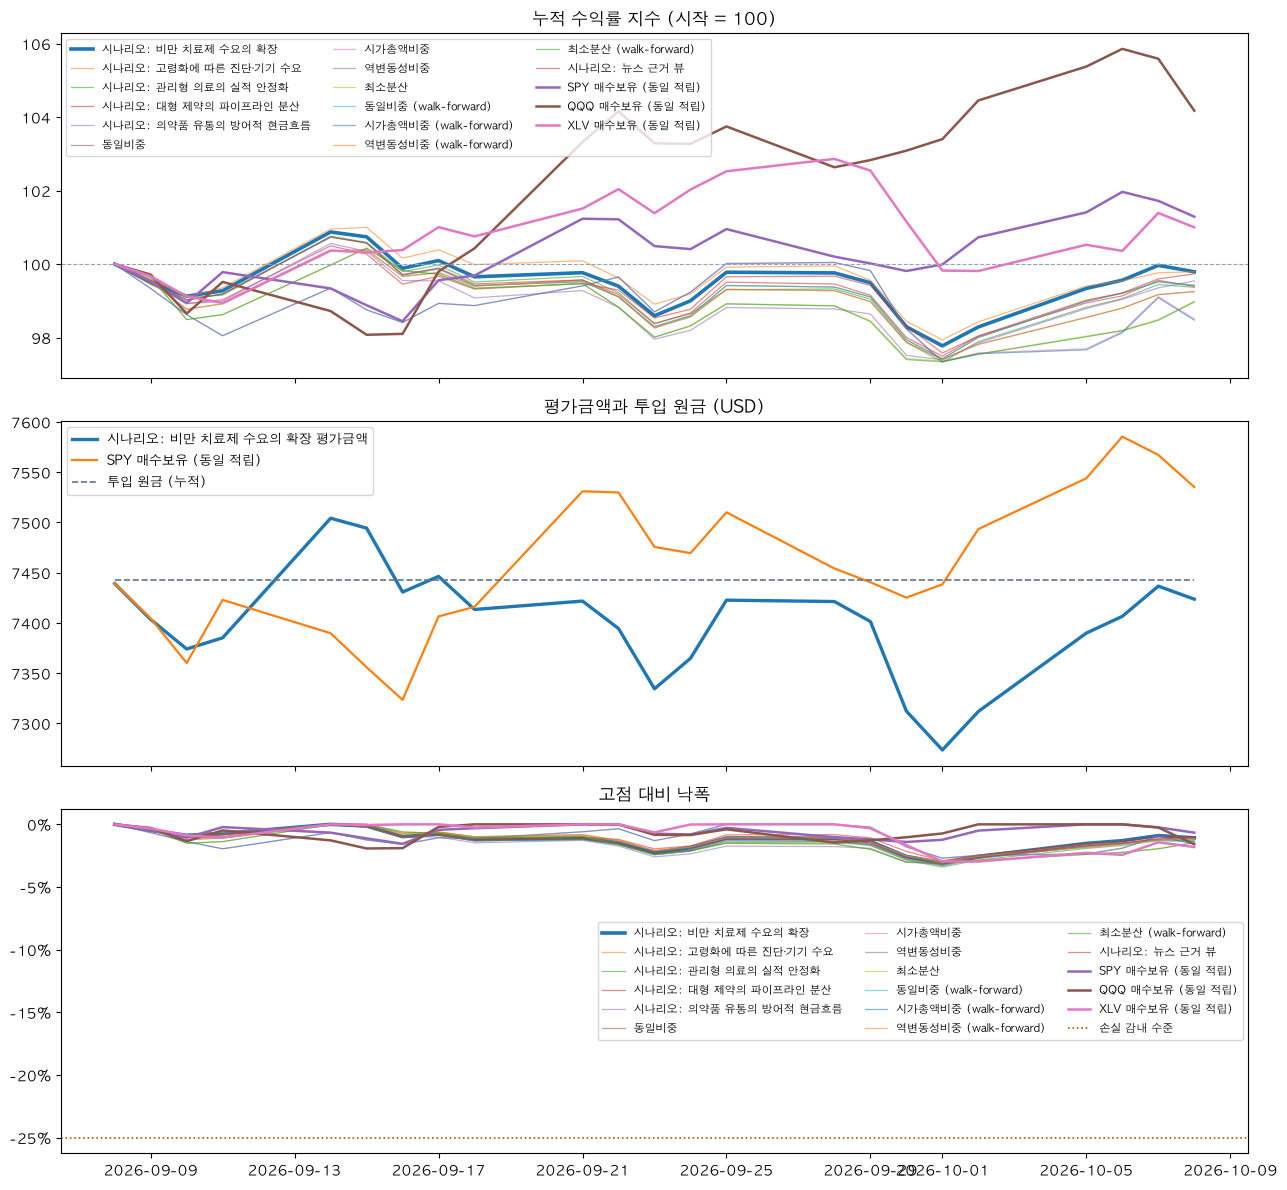

시나리오: 비만 치료제 수요의 확장 최대낙폭 -3.1%: 고점 2026-09-14 → 저점 2026-10-01 → 회복 기간 내 미회복 (고점 아래 24일)


In [8]:
dates = pd.to_datetime(BT["series_dates"]); series = {p["id"]: p for p in [*BT["portfolios"], *BT.get("benchmarks", [BT["benchmark"]]), *R["validation"].get("alternatives", [])]}
fig, axes = plt.subplots(3, 1, figsize=(13, 12), sharex=True)
for pid, p in series.items():
    lw = 2.6 if pid == chosen else (1.8 if p["kind"] == "benchmark" else 0.9); alpha = 1 if (pid == chosen or p["kind"] == "benchmark") else 0.55
    axes[0].plot(dates, p["series"]["index"], lw=lw, alpha=alpha, label=label(p))
    axes[2].plot(dates, p["series"]["drawdown"], lw=lw, alpha=alpha, label=label(p))
axes[0].axhline(100, color="#94a3b8", ls="--", lw=0.8); axes[0].set_title("누적 수익률 지수 (시작 = 100)"); axes[0].legend(ncol=3, fontsize=8)
cp = series[chosen]; led = {l["date"]: l["amount_usd"] for l in cp["contribution_ledger"]}; inv, cum = [], cp["money"]["initial_usd"]
for ds in BT["series_dates"]: cum += led.get(ds, 0.0); inv.append(cum)
axes[1].plot(dates, cp["series"]["value_usd"], lw=2.4, label=f"{label(cp)} 평가금액"); axes[1].plot(dates, series[BT["benchmark"]["id"]]["series"]["value_usd"], lw=1.6, label="SPY 매수보유 (동일 적립)")
axes[1].plot(dates, inv, lw=1.2, ls="--", color="#64748b", label="투입 원금 (누적)"); axes[1].set_title("평가금액과 투입 원금 (USD)"); axes[1].legend(fontsize=9)
axes[2].yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); axes[2].set_title("고점 대비 낙폭"); axes[2].axhline(-R["intent"]["risk_params"]["effective_max_drawdown"], color="#b45309", ls=":", lw=1.2, label="손실 감내 수준")
axes[2].legend(ncol=3, fontsize=8); plt.tight_layout(); plt.show()
mdd = cp["metrics"]["risk"]["mdd"]; print(f"{label(cp)} 최대낙폭 {cp['headline']['max_drawdown']:.1%}: 고점 {mdd['peak_date']} → 저점 {mdd['trough_date']} → 회복 {mdd['recovery_date'] or '기간 내 미회복'} (고점 아래 {mdd['underwater_days']}일)")

,2026
시나리오: 비만 치료제 수요의 확장,-0.2%
SPY 매수보유 (동일 적립),+1.3%
동일비중,-0.6%


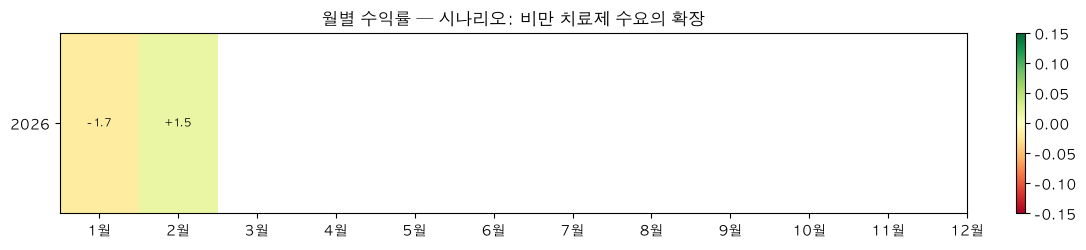

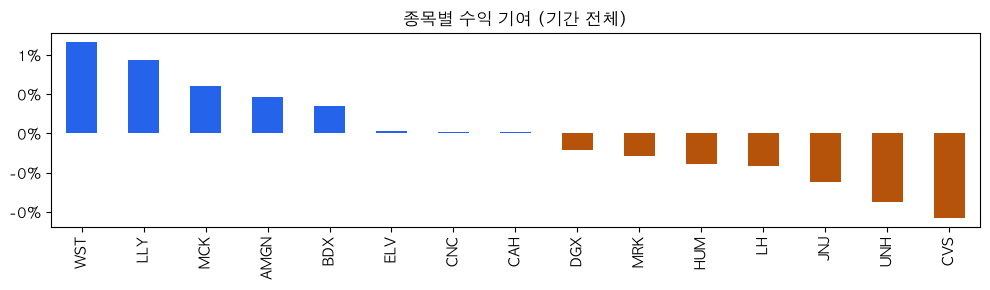

In [9]:
yr = pd.DataFrame({label(p): p["yearly_returns"] for p in [cp, series[BT["benchmark"]["id"]], series[P["targets"]["baseline"]["id"]]]}).T
display(yr.style.format("{:+.1%}", na_rep="–").set_caption("연도별 수익률 (첫해·마지막 해는 부분 기간)"))
mr = pd.DataFrame(cp["monthly_returns"]).pivot(index="year", columns="month", values="return")
fig, ax = plt.subplots(figsize=(11, 2.6)); im = ax.imshow(mr.values, cmap="RdYlGn", vmin=-0.15, vmax=0.15, aspect="auto")
ax.set_xticks(range(12)); ax.set_xticklabels([f"{m}월" for m in range(1, 13)]); ax.set_yticks(range(len(mr.index))); ax.set_yticklabels(mr.index)
for i in range(mr.shape[0]):
    for j in range(mr.shape[1]):
        v = mr.values[i, j]
        if not np.isnan(v): ax.text(j, i, f"{v*100:+.1f}", ha="center", va="center", fontsize=8)
ax.set_title(f"월별 수익률 — {label(cp)}"); plt.colorbar(im, ax=ax, fraction=0.02); plt.tight_layout(); plt.show()
contrib = pd.Series(cp["ticker_contribution"]).sort_values(ascending=False)
ax = contrib.plot.bar(figsize=(10, 3), color=["#2563eb" if v >= 0 else "#b45309" for v in contrib]); ax.yaxis.set_major_formatter(mpl.ticker.PercentFormatter(1.0, decimals=0)); ax.set_title("종목별 수익 기여 (기간 전체)"); plt.tight_layout(); plt.show()

### 리밸런싱 시점별 구성과 성과
각 리밸런싱일의 **조정 후 비중**(행)과 그 **직전 구간 성과**, 그 시점까지의 누적 지표입니다.

In [10]:
cps = cp["checkpoints"]
wt = pd.DataFrame({c["date"]: c["weights"]["after"] for c in cps}).T
display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption(f"리밸런싱 후 비중 — {label(cp)}"))
rows = []
for c in cps:
    sl, td = c["since_last"] or {}, c["to_date"] or {}
    rows.append({"날짜": c["date"], "구분": c["kind"], "평가금액": c["money"]["value_usd"], "투입 원금": c["money"]["net_invested_usd"], "구간 수익": sl.get("return"), "SPY 구간": sl.get("benchmark_return"),
                 "구간 최대낙폭": sl.get("max_drawdown"), "최고 종목": f"{sl['best']['ticker']} {sl['best']['return']:+.1%}" if sl else "", "최저 종목": f"{sl['worst']['ticker']} {sl['worst']['return']:+.1%}" if sl else "",
                 "누적 CAGR": td.get("cagr"), "누적 MDD": td.get("max_drawdown"), "누적 Sharpe": td.get("sharpe"), "거래": len(c["trades"]), "비용": c["commission_usd"]})
display(pd.DataFrame(rows).set_index("날짜").style.format({"평가금액": "{:,.0f}", "투입 원금": "{:,.0f}", "구간 수익": "{:+.1%}", "SPY 구간": "{:+.1%}", "구간 최대낙폭": "{:.1%}", "누적 CAGR": "{:+.1%}", "누적 MDD": "{:.1%}", "누적 Sharpe": "{:.2f}", "비용": "{:.2f}"}, na_rep="–"))

,CNC,LLY,CAH,MRK,AMGN,JNJ,WST,CVS,UNH,DGX,ELV,MCK,HUM,BDX,LH
2026-09-08,6.3%,11.3%,6.4%,4.2%,6.4%,6.6%,7.5%,6.4%,6.4%,6.5%,6.4%,6.4%,6.4%,6.4%,6.4%
2026-09-22,6.3%,11.3%,6.4%,4.2%,6.4%,6.6%,7.5%,6.4%,6.4%,6.5%,6.4%,6.4%,6.4%,6.4%,6.4%
2026-10-06,6.3%,11.3%,6.4%,4.2%,6.4%,6.6%,7.5%,6.4%,6.4%,6.5%,6.4%,6.4%,6.4%,6.4%,6.4%
2026-10-08,6.3%,11.4%,6.6%,4.3%,6.4%,6.6%,7.3%,6.5%,6.3%,6.5%,6.4%,6.5%,6.1%,6.4%,6.5%


,구분,평가금액,투입 원금,구간 수익,SPY 구간,구간 최대낙폭,최고 종목,최저 종목,누적 CAGR,누적 MDD,누적 Sharpe,거래,비용
날짜,,,,,,,,,,,,,
2026-09-08,rebalance,"7,439","7,443",–,–,–,,,–,–,–,15,3.72
2026-09-22,rebalance,"7,394","7,443",-0.6%,+1.2%,-1.5%,WST +9.9%,CVS -9.3%,-14.1%,-1.5%,-1.69,15,0.16
2026-10-06,rebalance,"7,407","7,443",+0.2%,+0.7%,-2.0%,HUM +8.7%,MRK -5.9%,-5.4%,-3.1%,-0.87,15,0.09
2026-10-08,closing,"7,424","7,443",+0.2%,-0.7%,-0.2%,CAH +2.4%,HUM -4.2%,-2.4%,-3.1%,-0.61,0,0.00


In [11]:
vd = [(label(p), v["type"], v["summary_ko"].split(" — ")[0], v["expected_return_annual"], v["realized"], "적중" if v["hit"] else "빗나감") for p in BT["portfolios"] for v in p["view_diagnostics"]]
if vd:
    display(pd.DataFrame(vd, columns=["시나리오", "유형", "뷰", "기대", "실제(12개월)", "방향"]).style.format({"기대": "{:+.0%}", "실제(12개월)": "{:+.1%}"}).set_caption("시나리오 뷰 사후 점검 (구성 후 12개월 실현 수익)"))

,시나리오,유형,뷰,기대,실제(12개월),방향
0,시나리오: 비만 치료제 수요의 확장,absolute,[절대] LLY +20%/년 (신뢰 0.38),+20%,+4.1%,빗나감
1,시나리오: 비만 치료제 수요의 확장,absolute,[절대] WST +21%/년 (신뢰 0.30),+21%,+7.6%,빗나감
2,시나리오: 비만 치료제 수요의 확장,relative,[상대] LLY > MRK +8%/년 (신뢰 0.36),+8%,+7.6%,적중
3,시나리오: 비만 치료제 수요의 확장,relative,[상대] WST > BDX +6%/년 (신뢰 0.28),+6%,+4.9%,적중
4,시나리오: 고령화에 따른 진단·기기 수요,absolute,[절대] DGX +12%/년 (신뢰 0.31),+12%,-1.6%,빗나감
5,시나리오: 고령화에 따른 진단·기기 수요,absolute,[절대] BDX +15%/년 (신뢰 0.29),+15%,+2.6%,빗나감
6,시나리오: 고령화에 따른 진단·기기 수요,relative,[상대] DGX > LH +5%/년 (신뢰 0.27),+5%,+1.7%,적중
7,시나리오: 고령화에 따른 진단·기기 수요,relative,[상대] BDX+DGX > CVS +7%/년 (신뢰 0.26),+7%,+9.1%,적중
8,시나리오: 관리형 의료의 실적 안정화,absolute,[절대] UNH +24%/년 (신뢰 0.28),+24%,-6.9%,빗나감
9,시나리오: 관리형 의료의 실적 안정화,absolute,[절대] ELV +23%/년 (신뢰 0.27),+23%,+0.2%,빗나감


## 6. 검증 — 사용자 기준(손실 감내 수준·목표 수익·제약)에 비춰 본 판정

In [12]:
V = R["validation"]; print("기준:", {k: V["criteria"][k] for k in ["max_drawdown", "target_annual_return", "benchmark", "volatility_preference", "max_weight_per_stock", "max_weight_per_sector", "min_holdings"]})
mat = pd.DataFrame({label(series[r["id"]]): {c["rule"] + " " + c["name_ko"]: c["status"] for c in r["checks"]} for r in V["results"]}).T
color = lambda s: "background-color:#dcfce7" if s == "pass" else ("background-color:#fef3c7" if s == "warn" else "background-color:#fee2e2")
display(mat.style.map(color).set_caption("규칙별 판정 (pass 통과 / warn 주의 / fail 미통과)"))
print("요약:", V["summary"]); print("추천:", V["recommended"]["id"] + " — " + V["recommended"]["reason_ko"] if V["recommended"] else "추천 없음 — " + "; ".join(V["warnings"]))
for alt in V.get("alternatives", []): print(f"대안 {alt['name_ko']}: {alt['reason_ko']} 판정 {alt['status']}")
inf = V["criteria"].get("selection_infeasibility")
if inf: print(f"종목 수 미달 사유: 섹터 상한 {inf['sector_cap']:.0%} 로 최대 {inf['max_feasible_n']}종목 (목표 {inf['target']}); 선택지: " + " / ".join(inf["options_ko"]))
chk = pd.DataFrame(next(r for r in V["results"] if r["id"] == chosen)["checks"])[["rule", "name_ko", "level", "status", "message_ko"]]
display(chk.set_index("rule").rename(columns={"name_ko": "항목", "level": "수준", "status": "판정", "message_ko": "측정 결과"}).style.set_caption(f"{label(cp)} 상세"))

기준: {'max_drawdown': 0.25, 'target_annual_return': 0.12, 'benchmark': 'SPY', 'volatility_preference': 'medium', 'max_weight_per_stock': 0.15, 'max_weight_per_sector': 1.0, 'min_holdings': 10}


,R1 최대낙폭,R2 목표수익,R3 비교지수 대비,R4 종목 상한(리밸런싱일),R4b 종목 상한(드리프트),R5 섹터 상한(리밸런싱일),R5b 섹터 상한(드리프트),R6 종목 수,R7 변동성 적합,R8 데이터 무결성
시나리오: 비만 치료제 수요의 확장,pass,info,warn,pass,pass,pass,pass,pass,info,pass
시나리오: 고령화에 따른 진단·기기 수요,pass,info,warn,pass,pass,pass,pass,pass,info,pass
시나리오: 관리형 의료의 실적 안정화,pass,info,warn,pass,pass,pass,pass,pass,info,pass
시나리오: 대형 제약의 파이프라인 분산,pass,info,warn,pass,pass,pass,pass,pass,info,pass
시나리오: 의약품 유통의 방어적 현금흐름,pass,info,warn,pass,pass,pass,pass,pass,info,pass
동일비중,pass,info,warn,pass,pass,pass,pass,pass,info,pass
시가총액비중,pass,info,warn,pass,pass,pass,pass,pass,info,pass
역변동성비중,pass,info,warn,pass,pass,pass,pass,pass,info,pass
최소분산,pass,info,warn,pass,pass,pass,pass,pass,info,pass
동일비중 (walk-forward),pass,info,warn,pass,pass,pass,pass,pass,info,pass


요약: {'n_pass': 0, 'n_warn': 14, 'n_fail': 0}
추천: bl_01 — 검증 실패 없는 포트폴리오 중 Sharpe 최고(-0.61). CAGR -2.4%, 최대낙폭 -3.1%, 최종 평가금액 7,424 USD.


,항목,수준,판정,측정 결과
rule,,,,
R1,최대낙폭,hard,pass,최대낙폭 3.1% ≤ 허용 25%
R2,목표수익,info,info,CAGR -2.4% vs 목표 12% (기간 수익률 -0.2%; 창이 1년 미만이라 참고만)
R3,비교지수 대비,soft,warn,SPY 대비 초과 CAGR -18.2%
R4,종목 상한(리밸런싱일),hard,pass,리밸런싱일 최대 종목 비중 11.3% vs 상한 15%
R4b,종목 상한(드리프트),soft,pass,리밸런싱 사이 종목 비중 드리프트 허용 범위 안
R5,섹터 상한(리밸런싱일),hard,pass,리밸런싱일 최대 섹터 비중 100.0% vs 상한 100%
R5b,섹터 상한(드리프트),soft,pass,리밸런싱 사이 섹터 드리프트 허용 범위 안
R6,종목 수,hard,pass,보유 종목 15개 vs 최소 10개
R7,변동성 적합,info,info,연변동성 10.4% vs 성향(medium) 상한 30% (창이 1년 미만이라 참고만)


## 6b. 뉴스가 바꾼 것 — walk-forward (리밸런싱마다 직전 2주 뉴스로 뷰를 새로 만든 결과)

In [13]:
WF = R["portfolio"].get("walkforward"); EVD = (R["portfolio"].get("news_evidence") or {}).get("all_evidence", {})
if not WF:
    print("walk-forward 결과 없음 (--news 로 실행한 경우에만 생성)")
else:
    bl = next(p for p in WF["portfolios"] if p["kind"] == "black_litterman"); base = next(p for p in WF["portfolios"] if p["id"] == "wf_equal_weight")
    rows = []
    for d in WF["dates"]:
        ns = WF["news_summary"][d]; views = bl["views_by_date"].get(d, []); w = bl["weights_by_date"][d]; b = base["weights_by_date"][d]
        top = sorted(((t, w[t] - b[t]) for t in w), key=lambda x: -abs(x[1]))[:3]
        rows.append({"리밸런싱일": d, "뉴스 창": f"{ns['window'][0]}~{ns['window'][1]}", "기사": ns["n_articles"], "뉴스 있는 종목": ns["n_tickers_with_news"],
                     "출처": ", ".join(f"{k} {v}" for k, v in ns["origin_counts"].items() if v), "뷰": len(views), "기준 대비 변화(상위 3)": ", ".join(f"{t} {x:+.1%}" for t, x in top) if views else "기준 비중 유지"})
    display(pd.DataFrame(rows).set_index("리밸런싱일"))
    vrows = [{"날짜": d, "뷰": v["summary_ko"].split(" — ")[0], "신뢰도": v["confidence"], "근거": ", ".join(v.get("evidence_ids", [])), "이유": v.get("rationale_ko", "")} for d in WF["dates"] for v in bl["views_by_date"].get(d, [])]
    if vrows: display(pd.DataFrame(vrows).set_index("날짜"))
    used = sorted({i for d in WF["dates"] for v in bl["views_by_date"].get(d, []) for i in v.get("evidence_ids", [])})
    if used:
        erows = [{"근거": i, "날짜": EVD[i]["published_at"], "종목": EVD[i]["ticker"], "출처": "팀 DB" if EVD[i].get("origin", "db") == "db" else "웹 검색", "발행사": EVD[i].get("publisher") or EVD[i].get("source"), "제목": EVD[i]["title"][:90], "url": EVD[i]["url"]} for i in used if i in EVD]
        display(pd.DataFrame(erows).set_index("근거"))
    wt = pd.DataFrame({d: bl["weights_by_date"][d] for d in WF["dates"]}).T
    display(wt.style.format("{:.1%}").background_gradient(cmap="Blues", axis=None).set_caption("뉴스 뷰 BL — 리밸런싱일별 타겟 비중"))
    for pid in [bl["id"], "wf_equal_weight"]:
        p = series.get(pid)
        if p: print(f"{p['name_ko']}: 기간 수익률 {p['headline']['period_return']:+.2%}, 최대낙폭 {p['headline']['max_drawdown']:.2%}, 최종 {p['headline']['final_value_usd']:,.0f} USD")

,뉴스 창,기사,뉴스 있는 종목,출처,뷰,기준 대비 변화(상위 3)
리밸런싱일,,,,,,
2026-09-08,2026-08-25~2026-09-08,9,5,web_search 9,4,"LLY +1.4%, MRK -1.2%, JNJ +0.7%"
2026-09-22,2026-09-08~2026-09-22,3,3,web_search 3,4,"JNJ +1.5%, MRK -1.0%, CVS +0.7%"
2026-10-06,2026-09-22~2026-10-06,147,15,db 147,4,"HUM -5.0%, DGX +4.6%, LH -3.7%"


,뷰,신뢰도,근거,이유
날짜,,,,
2026-09-08,[절대] LLY +15%/년 (신뢰 0.25),0.25,"web001, web002",릴리 실사용 연구에서 비만 고령자의 월 의료비가 12~18개월 시점에 25.4% 낮았다는 보도(web001)는 긍정적 수요·가치 신호지만...
2026-09-08,[절대] AMGN +14%/년 (신뢰 0.25),0.25,"web007, web004",암젠의 IMDELLTRA·IMFINZI 병용요법이 1차 치료 소세포폐암에서 전체생존기간 개선을 보였다는 보도(web007)를 긍정적으로 ...
2026-09-08,[상대] LLY > MRK +5%/년 (신뢰 0.25),0.25,"web001, web003","릴리의 비만 치료제 실사용 연구에서 고령자의 의료비 감소가 보고된 반면(web001), 머크 관련 헤드라인은 Medicaid 약가 합의 ..."
2026-09-08,[상대] AMGN > JNJ +4%/년 (신뢰 0.25),0.25,"web007, web004, web005","암젠 병용요법의 전체생존기간 개선 보도(web007)가 긍정적 차별화 근거이며, 암젠과 존슨앤드존슨 모두 Medicaid 약가 합의 관련..."
2026-09-22,[절대] UNH +21%/년 (신뢰 0.25),0.25,web012,UNH가 2026년 3분기 실적 발표일을 10월 13일로 안내하고 주당 2.32달러 배당 지급일을 9월 22일로 공지한 사실(web012...
2026-09-22,[상대] UNH > CVS +1%/년 (신뢰 0.20),0.20,web012,"UNH의 3분기 실적 발표 일정과 배당 지급 공지가 확인된 반면 CVS 관련 헤드라인은 없어, 확인 가능한 일정·주주환원 정보에 한해 U..."
2026-09-22,[상대] MRK > JNJ +0%/년 (신뢰 0.15),0.15,web010,"MRK가 모건스탠리 글로벌 헬스케어 컨퍼런스 참석을 알렸다는 사실(web010)만 반영하며, 참석 자체가 사업 성과를 뜻하지 않으므로 우..."
2026-09-22,[상대] AMGN > BDX +0%/년 (신뢰 0.15),0.15,web011,"AMGN이 컨퍼런스 발표 일정을 공지했고 R&D 책임자와 CFO가 참석 예정이라는 사실(web011)을 반영한 약한 상대 뷰이며, 발표 ..."
2026-10-06,[절대] LLY +18%/년 (신뢰 0.30),0.30,"ev21950, ev21943, ev21951, ev21942","췌장암 치료제 FDA 승리와 Jaypirca의 1차 치료 적응증 FDA 승인 보도(ev21950, ev21943)는 긍정적 신약 흐름을 ..."


,날짜,종목,출처,발행사,제목,url
근거,,,,,,
ev11258,2026-10-04,DGX,팀 DB,Simply Wall Street,How Investors May Respond To Quest Diagnostics (DGX) Solid Tumor Test Valida...,https://news.google.com/rss/articles/CBMi1gFBVV95cUxOemkwMDFwTUtPMzhnVXlVSmc...
ev20822,2026-10-05,HUM,팀 DB,Simply Wall Street,How Investors May Respond To Humana (HUM) Expanded Medicare Advantage Plans,https://news.google.com/rss/articles/CBMixwFBVV95cUxPbmhiZWI5eENaRTlQdVlDaVJ...
ev20824,2026-10-05,HUM,팀 DB,Bloomberg Law News,"Humana, HHS, Spar Over Medicare Advantage Payments in Court",https://news.google.com/rss/articles/CBMisgFBVV95cUxNb3czb0gxT2hSX29kMGpZZk1...
ev21815,2026-10-02,LH,팀 DB,HealthExec,Labcorp settles $2.3B data breach lawsuit brought by 44 states,https://news.google.com/rss/articles/CBMisAFBVV95cUxOMmVqVzUxYkNfdEtFRGtsM1h...
ev21942,2026-10-02,LLY,팀 DB,Pharmaceutical Executive,Foghorn Therapeutics & Eli Lilly Discontinue Development of FHD-909 | PharmExec,https://news.google.com/rss/articles/CBMioAFBVV95cUxPbjRPZkR3UkRKS1NyUVR4TjR...
ev21943,2026-10-02,LLY,팀 DB,Fierce Pharma,"With FDA approval, Lilly’s BTK drug Jaypirca enters first-line CLL",https://news.google.com/rss/articles/CBMimgFBVV95cUxQX21MMWZmNm1CZGEtak1VbGc...
ev21950,2026-10-05,LLY,팀 DB,Barron's,Eli Lilly Scores FDA Win for Pancreatic Cancer Drug. How It’s Moving Beyond ...,https://news.google.com/rss/articles/CBMitAFBVV95cUxOSXlRdDlzc2NYd0RwZUI2ZWF...
ev21951,2026-10-05,LLY,팀 DB,The Motley Fool,"Eli Lilly Has Been a Growth Beast, but This Is the Riskiest Part About Its S...",https://news.google.com/rss/articles/CBMivwFBVV95cUxQeXBhV0JGWDBSTGZRNlJZZkh...
ev22328,2026-10-02,MCK,팀 DB,Pharmaceutical Commerce,"Cardinal Health, McKesson Extend CVS Distribution Deals to 2032",https://news.google.com/rss/articles/CBMiqgFBVV95cUxPUUpFbXd5R1I2SFFtUW0tdmh...


,CNC,LLY,CAH,MRK,AMGN,JNJ,WST,CVS,UNH,DGX,ELV,MCK,HUM,BDX,LH
2026-09-08,6.3%,8.1%,6.7%,5.5%,7.0%,7.4%,6.5%,6.6%,6.5%,6.8%,6.4%,6.7%,6.4%,6.6%,6.6%
2026-09-22,6.3%,6.6%,6.8%,5.7%,6.3%,8.2%,6.5%,7.4%,6.3%,6.9%,6.5%,6.8%,6.4%,6.8%,6.7%
2026-10-06,6.2%,8.0%,7.2%,6.8%,6.6%,8.0%,6.5%,6.3%,5.8%,11.3%,6.1%,9.6%,1.7%,6.9%,3.0%


뉴스 뷰 Black-Litterman (walk-forward): 기간 수익률 -0.27%, 최대낙폭 -3.21%, 최종 7,419 USD
동일비중 (walk-forward): 기간 수익률 -0.58%, 최대낙폭 -3.29%, 최종 7,396 USD


## 6c. 지금 구성한다면 — 최신 가격·뉴스 기준 (백테스트 없음)

기준일 2026-10-08 · 뉴스 창 2026-09-24~2026-10-08 · 기사 148건 · 뉴스 있는 종목 15 · δ=7.4224 (market_implied)


,관점,뷰,근거 수,최대 변화,예상 수익,예상 변동성
시나리오,,,,,,
제약 파이프라인과 규제 리스크,릴리의 암 치료제 관련 승인 헤드라인은 비만·당뇨 이외의 파이프라인 확장 신호로 해석했습니다. 반면 머크는 유럽 일부 시장에서 Keytruda SC 판매를 막는 법원 결정이 보도돼 상대적으로 보수적인 뷰를 둡니다.,[절대] LLY +16%/년 (신뢰 0.30) / [절대] MRK -8%/년 (신뢰 0.25) / [상대] LLY > MRK +10%/년 (신뢰 0.30) / [상대] AMGN > MRK +6%/년 (신뢰 0.25),5,+5.0%,13.5%,14.2%
당뇨 관리 기기와 의료기기 역량,"당뇨 관리에서는 Dexcom의 제2형 당뇨 관련 보도와 Novo Nordisk와의 파트너십을 성장 기회로 보되, G7 모니터 관련 소송 보도를 위험 요인으로 반영했습니다. Becton Dickinson은 임상시험 결",[절대] DXCM +6%/년 (신뢰 0.20) / [절대] BDX +13%/년 (신뢰 0.30) / [상대] BDX > DXCM +8%/년 (신뢰 0.25) / [상대] WST > DXCM +4%/년 (신뢰 0.20),6,+2.2%,14.1%,14.2%
의료서비스 확장과 보험·메디케어 불확실성,"McKesson의 Option Care 인수 참여 보도는 가정용 주입 치료 서비스 확장 가능성으로 해석하되, 관련 거래의 성과나 수익성을 미리 단정하지 않습니다. Humana는 Medicare Stars 등급 결과에",[절대] MCK +14%/년 (신뢰 0.30) / [절대] HUM -6%/년 (신뢰 0.20) / [상대] MCK > CVS +7%/년 (신뢰 0.25) / [상대] CNC > HUM +5%/년 (신뢰 0.20),8,+3.7%,13.7%,14.0%
제약 포트폴리오 전환과 수술 혁신,"Johnson & Johnson의 수술 로봇·수술 인텔리전스 관련 보도는 의료기기 혁신 방향을 보여주지만, MedTech 역풍도 언급돼 강도를 제한했습니다. Viatris의 제네릭 중심에서 벗어나려는 파이프라인 전략",[절대] JNJ +10%/년 (신뢰 0.30) / [절대] VTRS +7%/년 (신뢰 0.25) / [상대] JNJ > VTRS +5%/년 (신뢰 0.25) / [상대] AMGN > VTRS +4%/년 (신뢰 0.20),5,+4.5%,13.9%,14.1%
의료 유통 계약과 진단 서비스,Cardinal Health의 CVS 유통 계약 연장 보도는 기존 유통 관계의 지속성을 뒷받침하는 신호로 해석했습니다. Labcorp의 전망 재확인과 Quest Diagnostics의 종양 검사 검증 보도는 각기 다,[절대] CAH +10%/년 (신뢰 0.30) / [절대] LH +6%/년 (신뢰 0.25) / [상대] CAH > CVS +5%/년 (신뢰 0.20) / [상대] LH > DGX +3%/년 (신뢰 0.20),6,+2.4%,13.9%,14.2%


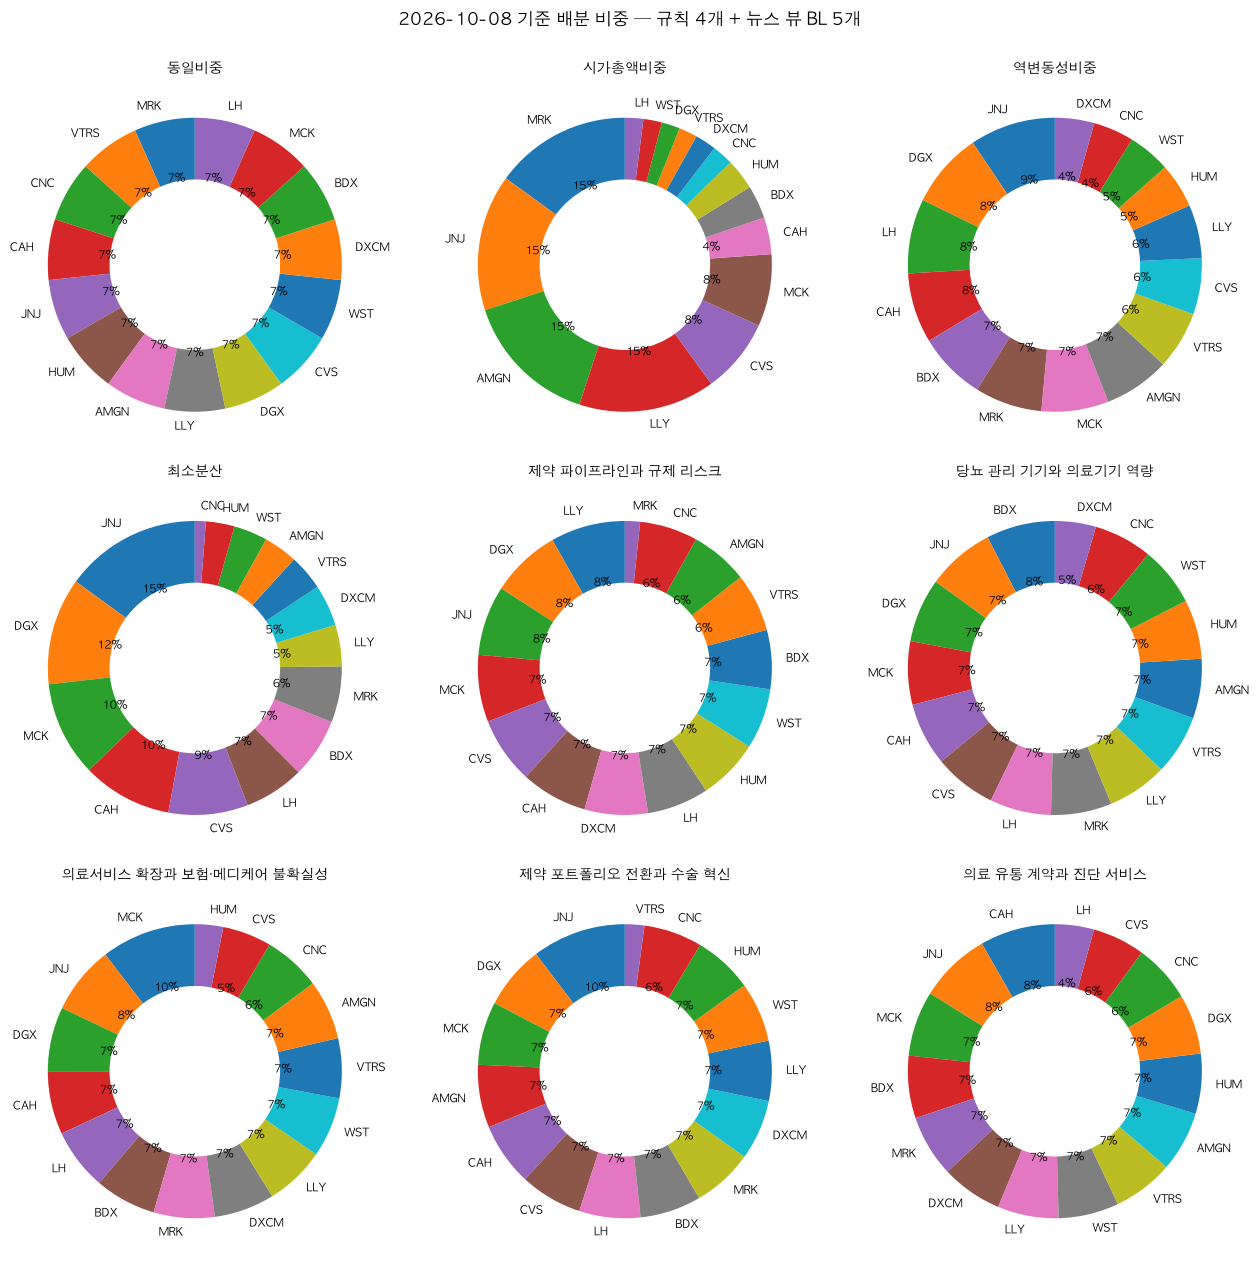

,비중,USD,원화
티커,,,
LLY,8.2%,612.68,"820,430"
DGX,7.7%,574.92,"769,870"
JNJ,7.7%,572.56,"766,710"
MCK,7.4%,550.03,"736,530"
CVS,7.3%,546.52,"731,830"
CAH,7.3%,546.46,"731,750"
DXCM,7.0%,519.40,"695,520"
LH,6.8%,507.48,"679,560"
HUM,6.7%,501.91,"672,100"


In [14]:
F = R["portfolio"].get("forward")
if not F:
    print("현재 구성 결과 없음")
else:
    nw = F.get("news_window"); print(f"기준일 {F['as_of']} · 뉴스 창 {nw['window'][0]}~{nw['window'][1]} · 기사 {nw['n_articles']}건 · 뉴스 있는 종목 {nw['n_tickers_with_news']} · δ={F['market_model']['delta']} ({F['market_model']['delta_source']})" if nw else f"기준일 {F['as_of']}")
    sc = pd.DataFrame([{"시나리오": p["title_ko"], "관점": p["portfolio_view"].split("\n")[0][:120], "뷰": " / ".join(v["summary_ko"].split(" — ")[0] for v in p["views_applied"]),
                        "근거 수": len({i for v in p["views_applied"] for i in v.get("evidence_ids", [])}), "최대 변화": max(abs(x) for x in p["delta_vs_baseline"].values()), "예상 수익": p["ex_ante"]["exp_return"], "예상 변동성": p["ex_ante"]["vol"]} for p in F["portfolios"]])
    display(sc.set_index("시나리오").style.format({"최대 변화": "{:+.1%}", "예상 수익": "{:.1%}", "예상 변동성": "{:.1%}"}))
    ports = F["templates"] + F["portfolios"]
    cols = 3; rows_ = -(-len(ports) // cols)
    fig, axes = plt.subplots(rows_, cols, figsize=(13, 4.2 * rows_))
    for ax, p in zip(axes.flat, ports):
        items = sorted([(t, w) for t, w in p["weights"].items() if w > 1e-6], key=lambda x: -x[1])
        ax.pie([w for _, w in items], labels=[t for t, _ in items], startangle=90, wedgeprops=dict(width=0.42), textprops={"fontsize": 8}, autopct=lambda v: f"{v:.0f}%" if v > 4 else "")
        ax.set_title(p.get("title_ko") or p["name_ko"], fontsize=10)
    for ax in list(axes.flat)[len(ports):]: ax.axis("off")
    plt.suptitle(f"{F['as_of']} 기준 배분 비중 — 규칙 4개 + 뉴스 뷰 BL {len(F['portfolios'])}개", y=1.0); plt.tight_layout(); plt.show()
    chosen = F["portfolios"][0] if F["portfolios"] else F["templates"][0]
    display(pd.DataFrame(chosen["allocation"]).rename(columns={"ticker": "티커", "weight": "비중", "usd": "USD", "krw": "원화"}).set_index("티커").style.format({"비중": "{:.1%}", "USD": "{:,.2f}", "원화": "{:,.0f}"}).set_caption(f"배분 금액 — {chosen['name_ko']} (투자금 {F['capital']['initial_amount_usd']:,.0f} USD)"))

## 7. 비용·조건·경고

In [15]:
u = R["llm_usage"]
if u.get("available"):
    display(pd.DataFrame(u["by_stage"]).T.style.format({"cost_usd": "{:.4f}"}).set_caption(f"분석 모델 호출 (누적, {u['model']}) — 합계 {u['total_cost_usd']:.4f} USD"))
display(pd.DataFrame(R["sources"])[["name", "what"]].rename(columns={"name": "출처", "what": "사용한 내용"}).set_index("출처"))
print("파라미터:", json.dumps(R["parameters"], ensure_ascii=False)[:600])
pd.DataFrame(R["warnings"]).rename(columns={"stage": "단계", "message": "경고"})

,calls,prompt_tokens,completion_tokens,cost_usd
02_intent,2.000000,13008.000000,4627.000000,0.0052
04_classify,4.000000,6366.000000,11798.000000,0.0073
06_explain,1.000000,950.000000,1814.000000,0.0010
00_descriptor,1.000000,3858.000000,3966.000000,0.0029
09_views,2.000000,4193.000000,6292.000000,0.0041
14a_interpret,4.000000,27806.000000,11888.000000,0.0122
14b_narrate,4.000000,54505.000000,19529.000000,0.0220
09n_wf_2026-09-08,1.000000,2887.000000,1475.000000,0.0014
09n_forward,1.000000,8543.000000,5197.000000,0.0045
09n_wf_2026-09-22,1.000000,2556.000000,1805.000000,0.0015


,사용한 내용
출처,
Yahoo Finance (yfinance),"일별 주가·수정주가·거래량 (2011-10 ~ 2026-10), 벤치마크 SPY"
Yahoo Finance (yfinance) 기업 개요,"회사 한 줄 소개(영문 사업 설명 첫 문장), 발행주식수, 재무제표 스냅샷"
Wikipedia,S&P 500 · NASDAQ-100 구성 종목과 GICS 세부산업
Wikipedia GICS,GICS 11 섹터 / 25 산업그룹 / 74 산업 / 163 세부산업 분류표
Yahoo Finance KRW=X,원/달러 환율 (투자금 환산 기준일 종가)
MyFinSight 파이프라인 계산,후보 검색·정량 스크린·비중 계산·Black-Litterman·백테스트(bt)·검증 규칙
분석 모델 (gpt-6-luna),"의도 해석, 테마 분류, 시나리오 뷰(뉴스 미연결 가정), 리포트 서술"


파라미터: {"portfolio": {"LOOKBACK_DAYS": 756, "SHRINKAGE": "ledoit_wolf", "TAU": 0.05, "RISK_AVERSION": {"conservative": 4.0, "moderate": 2.5, "aggressive": 1.5}, "OMEGA_METHOD": "he_litterman_confidence", "CONFIDENCE_FLOOR": 0.1, "ABS_RETURN_RANGE": [-0.5, 1.0], "REL_RETURN_RANGE": [0.0, 0.5], "TEMPLATES": ["equal_weight", "market_cap", "inverse_volatility", "min_variance"]}, "backtest": {"COMMISSION_BPS": 5, "INTEGER_POSITIONS": false, "RISK_FREE_RATE": 0.04, "TRADING_DAYS": 252, "DRIFT_TOLERANCE": 0.25, "CHECKPOINT_FREQ": "rebalance", "VOL_BANDS": {"low": 0.15, "medium": 0.3, "high": 9.99}}, "llm": 


,단계,경고
0,02,theme obesity_diabetes_treatments: dropped tickers outside universe ['NVO']
1,12,window of 23 trading days < 252: R2/R7 are informational only (annualized fi...
2,12,alternative skipped: chosen portfolio already within the drawdown tolerance
